In [1]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="gpt-oss:120b-cloud")
print('Model is ready to use!')

c:\Users\ak60492\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model is ready to use!


In [2]:
# Tools definition
from langchain_community.tools import tool

@tool
def get_weather(city: str) -> str:
    """Get weather for a city"""
    return f"The weather in the city {city} is Sunny"

@tool
def get_best_stock() -> str:
    """Returns the best stock to invest in"""
    return f"The best stock to invest in is Zensar"

@tool
def purchase_stock(stock: str, quantity: int) -> str:
    """Purchases a given stock for the specified quantity"""
    return f"Purchased {quantity} shares of {stock}"

ALL_TOOLS = [get_weather, get_best_stock, purchase_stock]
SENSITIVE_TOOLS = {"purchase_stock"}

print('Tools are ready')

Tools are ready


In [3]:
# STEP-1: Define the state
from typing import TypedDict, Annotated
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages

class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

print('Graph state is ready..')

Graph state is ready..


In [4]:
# STEP-2: Define the nodes
from langchain_core.messages import SystemMessage, ToolMessage
from langgraph.types import Command, interrupt

model_with_tools = model.bind_tools(ALL_TOOLS)

HITL_SYSTEM_PROMPT = SystemMessage(content=(
    "You have access to get_weather, get_best_stock, and purchase_stock tools. "
    "When the user asks to find best stock , immediately call the get_best_stock tool. "
    "When the user asks to purchase stock, immediately call the purchase_stock "
    "tool with the requested stock and quantity - do not ask the user to confirm "
    "in plain text first. A human reviewer approves or denies the purchase_stock tool call"
    "automatically before it executes, so your job is only to call the tool."
    
))

def assistant(state: AgentState) -> dict:
    """One graph node: call the model using current messages"""
    response = model_with_tools.invoke([HITL_SYSTEM_PROMPT] + state['messages'])
    return {"messages": [response]}

def route_after_assistant(state: AgentState) -> str:
    """Route to the tool only when model produces tool calls"""
    last_message = state['messages'][-1]
    tool_calls = getattr(last_message, "tool_calls", None)
    if not tool_calls:
        return "end"
    if any(tool_call['name'] in SENSITIVE_TOOLS for tool_call in tool_calls):
        return "human_review"
    return "tools"

def human_review(state: AgentState) -> Command:
    """Human review node: asks for human approval"""
    last_message = state['messages'][-1]
    tool_call = last_message.tool_calls[0]

    # Pause the graph execution for human review and wait for approval
    decision = interrupt({
        "question": "Shall I really purchase this stock?",
        "tool": tool_call['name'],
        "args": tool_call['args']
    })

    if decision == "approve":
        return Command(goto="tools")

    denial = ToolMessage(
        content="Human has rejected purchasing this stock",
        tool_call_id=tool_call['id']
    )
    
    return Command(goto="assistant", update={"messages": [denial]})

print('Graph Nodes are ready')

Graph Nodes are ready


Graph is ready...


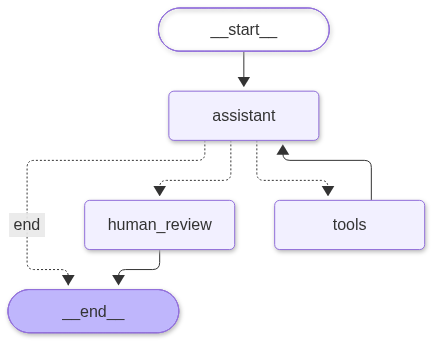

In [ ]:
# STEP-3: Add edges and build the graph
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver

short_term_memory = MemorySaver()

graph_builder = StateGraph(AgentState)

# Node registration
graph_builder.add_node("assistant", assistant)
graph_builder.add_node("human_review", human_review)
graph_builder.add_node("tools", ToolNode(ALL_TOOLS))

# Add edges
graph_builder.add_edge(START, "assistant")
graph_builder.add_conditional_edges(
    "assistant", 
    route_after_assistant,
    {
        "human_review": "human_review",
        "tools": "tools",
        "end": END

    }
)
graph_builder.add_edge("tools", "assistant")

graph = graph_builder.compile(checkpointer=short_term_memory)
print('Graph is ready...')
graph

In [7]:
hitl_config = {"configurable": {"thread_id": "stock_session"}}
response = graph.invoke({
    "messages": [
        {"role": "user", "content": "Which is the capital of India?"}
    ]
},hitl_config
)
response

{'messages': [HumanMessage(content='Which is the capital of India?', additional_kwargs={}, response_metadata={}, id='58a837c2-38da-480b-a40e-dfab7b8560fb'),
  AIMessage(content='The capital of India is **New\u202fDelhi**.', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-11-03T09:43:56.203142025Z', 'done': True, 'done_reason': 'stop', 'total_duration': 270523317, 'load_duration': None, 'prompt_eval_count': 272, 'prompt_eval_duration': None, 'eval_count': 41, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a1a0cb-346c-7102-b3d8-05d885333eda-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 272, 'output_tokens': 41, 'total_tokens': 313})]}

In [12]:
hitl_config = {"configurable": {"thread_id": "stock_session"}}
response = graph.invoke({
    "messages": [
        {"role": "user", "content": "Please purchase Zensar stocks for 10 shares."}
    ]
},hitl_config
)

if "__interrupt__" in response:
    print("Graph execution paused for human review...")
    print(response["__interrupt__"])
else:
    print('Graph execution completed without human review.')
    print(response)


Graph execution paused for human review...
[Interrupt(value={'question': 'Shall I really purchase this stock?', 'tool': 'purchase_stock', 'args': {'quantity': 10, 'stock': 'Zensar'}}, id='38d775ce9fceb3e8d85c36157a1ddcb8')]


In [11]:
approve_command = Command(resume="approve")
approve_response = graph.invoke(approve_command, hitl_config)
approve_response

{'messages': [HumanMessage(content='Which is the capital of India?', additional_kwargs={}, response_metadata={}, id='58a837c2-38da-480b-a40e-dfab7b8560fb'),
  AIMessage(content='The capital of India is **New\u202fDelhi**.', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-11-03T09:43:56.203142025Z', 'done': True, 'done_reason': 'stop', 'total_duration': 270523317, 'load_duration': None, 'prompt_eval_count': 272, 'prompt_eval_duration': None, 'eval_count': 41, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a1a0cb-346c-7102-b3d8-05d885333eda-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 272, 'output_tokens': 41, 'total_tokens': 313}),
  HumanMessage(content='Which is the best stock to invest in?', additional_kwargs={}, response_metadata={}, id='251052ac-999b-4566-bb9d-ffc61ff713c0'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': '

In [13]:
deny_command = Command(resume="deny")
deny_response = graph.invoke(deny_command, hitl_config)
deny_response

{'messages': [HumanMessage(content='Which is the capital of India?', additional_kwargs={}, response_metadata={}, id='58a837c2-38da-480b-a40e-dfab7b8560fb'),
  AIMessage(content='The capital of India is **New\u202fDelhi**.', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-11-03T09:43:56.203142025Z', 'done': True, 'done_reason': 'stop', 'total_duration': 270523317, 'load_duration': None, 'prompt_eval_count': 272, 'prompt_eval_duration': None, 'eval_count': 41, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a1a0cb-346c-7102-b3d8-05d885333eda-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 272, 'output_tokens': 41, 'total_tokens': 313}),
  HumanMessage(content='Which is the best stock to invest in?', additional_kwargs={}, response_metadata={}, id='251052ac-999b-4566-bb9d-ffc61ff713c0'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': '